# Step 14 — 1D Gravity Waves (Linear Shallow Water)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step14_gravity_waves_1d.ipynb)

*Part of the rotating shallow-water series; moved from somax's tutorial series.*

The linear shallow-water equations describe gravity waves in a thin layer of fluid. A height perturbation splits into two waves propagating at the phase speed $c = \sqrt{g H_0}$.

**What you'll learn:**

1. How to create a 1D linear shallow-water model in sesmax
2. How a height perturbation propagates as gravity waves, and how to verify their speed
3. How to differentiate through the model

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

Linearised about a layer of depth $H_0$ at rest, with no rotation here, the height perturbation and the velocity obey

$$
\frac{\partial h}{\partial t} + H_0 \frac{\partial u}{\partial x} = 0
$$

$$
\frac{\partial u}{\partial t} + g \frac{\partial h}{\partial x} = 0
$$

Eliminating $u$ gives the wave equation $\partial^2 h / \partial t^2 = c^2 \partial^2 h / \partial x^2$ with $c = \sqrt{g H_0}$. On an initial Gaussian at rest, its exact solution is two half-height copies travelling apart at $\pm c$:

$$
h(x, t) = \frac{1}{2} \left[h_0(x - c t) + h_0(x + c t)\right]
$$

### Symbols

Unlike the earlier steps, this page is dimensional, in SI units.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$ | spatial coordinate (m) | $\mathbb{R}$ |
| $t$ | time (s) | $\mathbb{R}$ |
| $h(x, t)$, $h_0(x)$ | height perturbation and its initial value (m) | $\mathbb{R}$ |
| $u(x, t)$, $v(x, t)$ | velocity along and across $x$ (m/s); $v$ stays zero without rotation | $\mathbb{R}$ |
| $g$, $H_0$ | gravity (m/s²) and mean depth (m) | $\mathbb{R}_{>0}$ |
| $c$ | phase speed (m/s) | $\mathbb{R}_{>0}$ |
| $\mu_0$, $\sigma_0$ | centre and width of the initial Gaussian (m) | $\mathbb{R}$, $\mathbb{R}_{>0}$ |
| $L_x$ | domain length (m) | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x}$, $N_T$ | number of interior cells and of saved snapshots | count |
| $\Delta x$, $\Delta t$ | grid spacing (m) and time step (s) | $\mathbb{R}_{>0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

A 1D domain of length 2000 km with 400 cells. The mean depth is 100 m, which gives the phase speed printed below. Setting `f0=0` turns rotation off.

In [4]:
# Shapes: N_Ωx = 400 interior cells

num_cells = 400
domain_length = 2.0e6
gravity = 9.81
mean_depth = 100.0

# today (sesmax_core)
model = sxt.LinearShallowWater1D.create(
    nx=num_cells, Lx=domain_length, g=gravity, f0=0.0, H0=mean_depth
)

# c = √(g H₀)
phase_speed = jnp.sqrt(gravity * mean_depth)  # → ()
print(f"Phase speed: c = sqrt(g H0) = {float(phase_speed):.1f} m/s")
print(f"Grid spacing: dx = {model.grid.dx / 1e3:.1f} km")

Phase speed: c = sqrt(g H0) = 31.3 m/s
Grid spacing: dx = 5.0 km


## 2. Initial condition

A Gaussian height perturbation centred in the domain, with the fluid at rest.

In [5]:
# Shapes: N_Ωx = 400 interior cells; arrays carry N_Ωx + 2 = 402 with the ghosts

interior = slice(1, -1)
bump_centre = domain_length / 2.0
bump_width = domain_length / 20.0

# xₙ = n Δx
position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_Ωx + 2,)
# zₙ = (xₙ − μ₀) / σ₀
standardised = (position - bump_centre) / bump_width  # → (N_Ωx + 2,)
# h₀(x) = exp(−z² / 2)
initial_height = jnp.exp(-0.5 * standardised**2)  # → (N_Ωx + 2,)
at_rest = jnp.zeros_like(initial_height)  # → (N_Ωx + 2,)
# today (sesmax_core)
initial_state = sxt.LinearSW1DState(h=initial_height, u=at_rest, v=at_rest)

## 3. Forward simulation

We integrate for about 18 hours, which is roughly one transit of the domain at speed $c$, and save 200 snapshots. The waves leave one side and re-enter from the other because the boundaries are periodic.

In [6]:
# Shapes: N_T = 200 saved snapshots; N_Ωx + 2 = 402 cells with the ghosts

end_time = 6.5e4
# tₖ = k t₁ / (N_T − 1)
save_times = jnp.linspace(0.0, end_time, 200)  # → (N_T,)
# Δt = 0.5 Δx / c, a Courant number of one half
time_step = 0.5 * model.grid.dx / phase_speed  # → ()

# today (sesmax_core, diffrax)
solution = model.integrate(  # h, u, v → (N_T, N_Ωx + 2) each
    initial_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)
print(f"All finite: {bool(jnp.all(jnp.isfinite(solution.ys.h)))}")

All finite: True


## 4. Visualise the waves

The left panel shows the height at a few times, and the right panel is a Hovmöller diagram of the whole run. The two straight bands, of slope $\pm c$, are the waves.

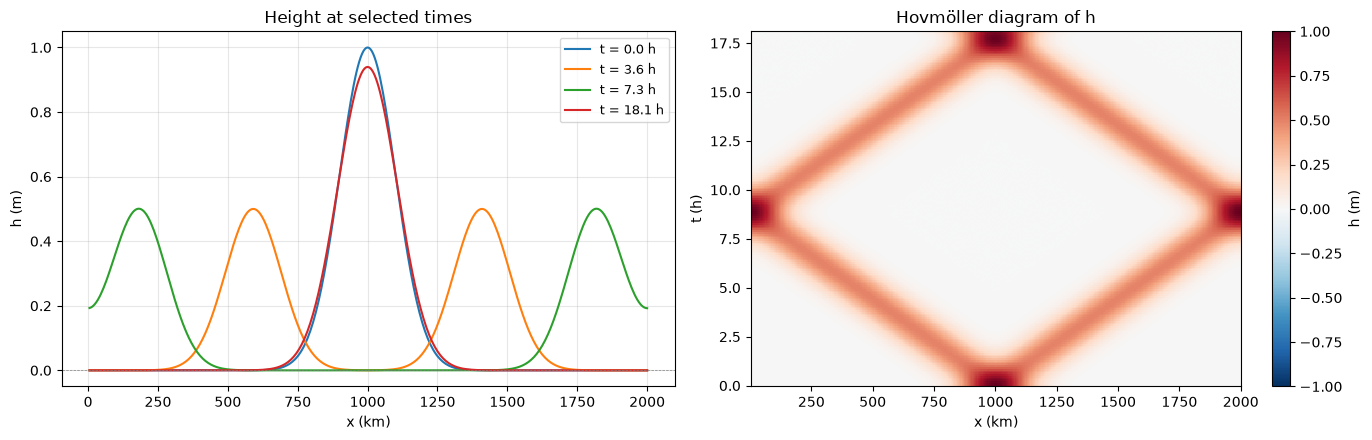

In [7]:
position_km = position[interior] / 1e3  # → (N_Ωx,)
time_hours = save_times / 3600.0  # → (N_T,)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
for colour, snapshot in enumerate([0, 40, 80, 199]):
    ax.plot(
        position_km,
        solution.ys.h[snapshot, interior],
        lw=1.5,
        color=f"C{colour}",
        label=f"t = {float(time_hours[snapshot]):.1f} h",
    )
ax.axhline(0.0, color="gray", ls="--", lw=0.5)
ax.set_xlabel("x (km)")
ax.set_ylabel("h (m)")
ax.set_title("Height at selected times")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
mesh = ax.pcolormesh(
    position_km,
    time_hours,
    solution.ys.h[:, interior],
    cmap="RdBu_r",
    vmin=-1.0,
    vmax=1.0,
    shading="auto",
)
ax.set_xlabel("x (km)")
ax.set_ylabel("t (h)")
ax.set_title("Hovmöller diagram of h")
plt.colorbar(mesh, ax=ax, label="h (m)")

plt.tight_layout()
plt.show()

## 5. Phase-speed verification

After time $t$, the right-moving peak should be at $\mu_0 + c t$ and the left-moving one at $\mu_0 - c t$, wrapped around the domain. We compare the final height against that two-peak solution.

In [8]:
# Shapes: N_Ωx = 400 interior cells

interior_position = position[interior]  # → (N_Ωx,)
# μ₊ = (μ₀ + c t₁) mod L_x
right_peak = (bump_centre + phase_speed * end_time) % domain_length  # → ()
# μ₋ = (μ₀ − c t₁) mod L_x
left_peak = (bump_centre - phase_speed * end_time) % domain_length  # → ()
# h₊(x) = exp(−(x − μ₊)² / (2σ₀²))
right_wave = jnp.exp(-0.5 * ((interior_position - right_peak) / bump_width) ** 2)
# h₋(x) = exp(−(x − μ₋)² / (2σ₀²))
left_wave = jnp.exp(-0.5 * ((interior_position - left_peak) / bump_width) ** 2)
# hᵉˣᵃᶜᵗ(x, t₁) = (h₊ + h₋) / 2
exact_height = 0.5 * (right_wave + left_wave)  # → (N_Ωx,)

final_height = solution.ys.h[-1, interior]  # → (N_Ωx,)
# r = ∑ h hᵉˣᵃᶜᵗ / √(∑ h² ∑ (hᵉˣᵃᶜᵗ)²)
inner = einx.dot("[x], [x] ->", final_height, exact_height)  # → ()
norm_final = einx.dot("[x], [x] ->", final_height, final_height)  # → ()
norm_exact = einx.dot("[x], [x] ->", exact_height, exact_height)  # → ()
correlation = inner / jnp.sqrt(norm_final * norm_exact)  # → ()
print(f"Correlation with the exact solution: {float(correlation):.4f}")

Correlation with the exact solution: 1.0000


## 6. Differentiability

`eqx.filter_grad` flows through the model parameters. Here we take the gradient of $\mathcal{L} = \sum_n h_n^2$ with respect to the viscosity and the drag, both zero in this model, over a 1000 s window.

In [9]:
# today (equinox)
@eqx.filter_grad
def height_gradient(model):
    """∂ℒ/∂(parameters), for ℒ = ∑ₙ h(xₙ, 1000 s)²."""
    # today (sesmax_core, diffrax)
    window = model.integrate(initial_state, t0=0.0, t1=1000.0, dt=time_step)
    # ℒ = ∑ₙ hₙ²
    return jnp.sum(window.ys.h**2)


model_gradients = height_gradient(model)
print(f"dL/d(viscosity) = {float(model_gradients.params.lateral_viscosity):.6f}")
print(f"dL/d(drag)      = {float(model_gradients.params.bottom_drag):.6f}")

dL/d(viscosity) = 0.000000
dL/d(drag)      = 530.228088


## Summary

| Concept | sesmax API |
| --- | --- |
| Create the model | `LinearShallowWater1D.create(nx, Lx, g, f0, H0)` |
| Initial state | `LinearSW1DState(h=..., u=..., v=...)` |
| Forward simulation | `model.integrate(state0, t0, t1, dt, saveat=...)` |
| Gradient with respect to the parameters | `eqx.filter_grad(loss)(model)` |

- The linear shallow-water equations support gravity waves at speed $c = \sqrt{g H_0}$.
- A Gaussian splits into two counter-propagating waves of half the height.
- The model is differentiable through its integration.

**Next:** [Step 15 — 1D Nonlinear Shallow Water](step15_shallow_water_1d.ipynb)